# 01 · Data understanding

**Owner:** Aayush · **Phase 1** of the StayScope pipeline

This notebook gets to know both datasets **before** any cleaning or modelling:

| Dataset | Role | File |
|---|---|---|
| **A** | Primary: 5,000 customers with the ground-truth `churned` label | `data/raw/netflix_customer_churn.csv` |
| **B** | Supplementary: 1,000 customers with engagement attributes | `data/raw/netflix_large_user_data.xlsx` |

**Contents**
1. Setup and loading
2. Schema
3. Data quality: missing values, duplicates, invalid values, derived and redundant columns, outliers
4. Target balance
5. Dataset A: numeric features vs churn
6. Dataset A: categorical features vs churn
7. Dataset B: features vs churn
8. Dataset A vs Dataset B: the common features we will match on
9. How much churn signal does each dataset hold?
10. Key findings and implications for the next phases

Nothing here modifies the data. Every decision is carried out in notebook 02 (cleaning) and notebook 03 (feature mapping).
Every figure is also saved to `reports/figures/01_*.png`.

## 1. Setup and loading

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from churn import config, data, eda
from churn.plotting import (CHURN, DIVERGING, NEUTRAL, RETAINED, savefig, set_style)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
config.ensure_dirs()

TARGET, ID = config.TARGET, config.ID_COL
STATUS_PALETTE = {"Retained": RETAINED, "Churned": CHURN}
A_COLOR, B_COLOR = "#7C9CF5", "#A78BFA"

In [2]:
a = data.load_a()
b = data.load_b()

# Readable status columns for plotting (the original columns are left untouched)
a["status"] = a[TARGET].map({0: "Retained", 1: "Churned"})
b["status"] = b["churn_b"].map({"No": "Retained", "Yes": "Churned"})
b["churn_b_flag"] = (b["churn_b"] == "Yes").astype(int)

print(f"Dataset A: {a.shape[0]:,} rows x {a.shape[1] - 1} columns")
print(f"Dataset B: {b.shape[0]:,} rows x {b.shape[1] - 2} columns (columns renamed to snake_case by data.load_b)")

Dataset A: 5,000 rows x 14 columns
Dataset B: 1,000 rows x 16 columns (columns renamed to snake_case by data.load_b)


In [3]:
a.drop(columns='status').head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.730,29,Africa,TV,8.990,1,Gift Card,1,0.490,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.700,19,Europe,Mobile,13.990,1,Gift Card,5,0.030,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.320,10,Asia,TV,13.990,0,Crypto,2,1.480,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.510,12,Oceania,TV,17.990,1,Crypto,2,0.350,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.890,13,Africa,Mobile,13.990,1,Crypto,2,0.130,Action


In [4]:
b.drop(columns=['status', 'churn_b_flag']).head()

,customer_id,subscription_length_months,satisfaction_score,daily_watch_time,engagement_rate,device,favorite_genre,region,payment_history,subscription_type,churn_b,support_queries,age,monthly_income,promo_offers_used,number_of_profiles
0,C00001,12,10,4.850,4,Tablet,Action,Europe,On-Time,Basic,No,10,33,6250,5,2
1,C00002,12,8,1.750,9,Laptop,Thriller,Europe,On-Time,Basic,Yes,9,28,7018,1,5
2,C00003,3,4,2.750,9,Smart TV,Comedy,Asia,On-Time,Premium,Yes,3,18,1055,1,5
3,C00004,3,7,3.000,9,Smart TV,Drama,Europe,Delayed,Premium,No,5,32,6707,5,4
4,C00005,24,2,1.370,5,Mobile,Drama,North America,On-Time,Standard,Yes,2,59,1506,3,5


## 2. Schema

`kind` is how we will treat each column. `number_of_profiles` is stored as an integer but has only 5 values,
so it can be treated as either ordinal-numeric or categorical. We keep it numeric.

In [5]:
print("Dataset A")
display(eda.schema_summary(a.drop(columns="status")))

Dataset A


,column,dtype,kind,unique,missing,missing_pct,example
0,customer_id,str,categorical,5000,0,0.000,a9b75100-82a8-427a-a208-72f24052884a
1,age,int64,numeric,53,0,0.000,51
2,gender,str,categorical,3,0,0.000,Other
3,subscription_type,str,categorical,3,0,0.000,Basic
4,watch_hours,float64,numeric,2343,0,0.000,14.730
5,last_login_days,int64,numeric,61,0,0.000,29
6,region,str,categorical,6,0,0.000,Africa
7,device,str,categorical,5,0,0.000,TV
8,monthly_fee,float64,numeric,3,0,0.000,8.990
9,churned,int64,numeric,2,0,0.000,1


In [6]:
print("Dataset B")
display(eda.schema_summary(b.drop(columns=["status", "churn_b_flag"])))

Dataset B


,column,dtype,kind,unique,missing,missing_pct,example
0,customer_id,str,categorical,1000,0,0.000,C00001
1,subscription_length_months,int64,numeric,5,0,0.000,12
2,satisfaction_score,int64,numeric,10,0,0.000,10
3,daily_watch_time,float64,numeric,406,0,0.000,4.850
4,engagement_rate,int64,numeric,10,0,0.000,4
5,device,str,categorical,5,0,0.000,Tablet
6,favorite_genre,str,categorical,7,0,0.000,Action
7,region,str,categorical,5,0,0.000,Europe
8,payment_history,str,categorical,2,0,0.000,On-Time
9,subscription_type,str,categorical,3,0,0.000,Basic


## 3. Data quality

### 3.1 Missing values and duplicates

In [7]:
quality = pd.DataFrame({
    "Dataset A": eda.quality_report(a.drop(columns="status"), ID),
    "Dataset B": eda.quality_report(b.drop(columns=["status", "churn_b_flag"]), ID),
})
quality

,Dataset A,Dataset B
rows,5000,1000
columns,14,16
missing_cells,0,0
duplicate_rows,0,0
duplicate_ids,0,0


Both datasets are complete: no missing cells, no duplicate customers, and no rows that are duplicated once
the ID is ignored. The cleaning work in notebook 02 is about **invalid values and redundancy**, not imputation.

### 3.2 Is `avg_watch_time_per_day` a derived column?
Its values looked suspiciously tied to `watch_hours` and `last_login_days`, so we test the hypothesis
`avg_watch_time_per_day = watch_hours / (last_login_days + 1)`.

In [8]:
reconstructed = a["watch_hours"] / (a["last_login_days"] + 1)
match = (reconstructed - a["avg_watch_time_per_day"]).abs() < 0.011   # values are stored to 2 decimals
print(f"Rows where the formula reproduces the column: {match.mean():.1%}")

invalid = a[a["avg_watch_time_per_day"] > 24]
print(f"Rows claiming more than 24 h of viewing per day: {len(invalid)}")
invalid[[ID, "watch_hours", "last_login_days", "avg_watch_time_per_day", TARGET]].sort_values(
    "avg_watch_time_per_day", ascending=False)

Rows where the formula reproduces the column: 100.0%
Rows claiming more than 24 h of viewing per day: 10


,customer_id,watch_hours,last_login_days,avg_watch_time_per_day,churned
2017,23e2a122-9e50-41d8-a434-c25675765f79,98.420,0,98.420,0
1219,45ea1095-e06b-4a1c-a0b7-c3671c9f006a,52.800,0,52.800,0
2564,511d9a10-669b-4283-bc6d-40c10a595b43,34.530,0,34.530,0
4792,88a98e69-9e49-4d28-98d7-1e0b1bce6138,32.880,0,32.880,0
4078,9adb0b11-3199-438c-9b3c-59dee22c6b27,32.810,0,32.810,0
4805,b906246e-44aa-441f-85c5-fc2aa946b0cb,29.550,0,29.550,0
3641,64d85f24-42f8-48b1-8675-590db42d23e5,28.660,0,28.660,0
4285,3878e4e3-2960-4b36-b25c-f90ddd01b5d8,54.530,1,27.270,0
4845,d202349e-dd45-42e7-84a9-fa604082763f,26.980,0,26.980,0
647,c350d5a0-fef7-4281-b752-42162d72bd05,25.150,0,25.150,0


The formula matches **100%** of rows. So `avg_watch_time_per_day` adds no new information; it is a ratio
of two columns we already have. The `+ 1` in the denominator means customers who logged in today
(`last_login_days = 0`) get their *entire* `watch_hours` counted as one day. That produces the impossible
values above 24 h/day. **Decision for notebook 02:** treat these rows as invalid (cap or recompute) and
consider dropping the column from modelling to avoid double-counting.

### 3.3 Is `monthly_fee` redundant?

In [9]:
a.groupby("subscription_type")["monthly_fee"].agg(["unique", "nunique"])

,unique,nunique
subscription_type,,
Basic,[8.99],1
Premium,[17.99],1
Standard,[13.99],1


Every plan has exactly one fee, so `monthly_fee` is a one-to-one recoding of `subscription_type`.
Keeping both gives the models the same information twice. **Decision for notebook 02:** keep
`subscription_type` (it is shared with Dataset B, which matters for matching) and drop `monthly_fee`,
or keep it only as an ordinal stand-in for the plan.

### 3.4 Value ranges and outliers (IQR rule, k = 1.5)

In [10]:
print("Dataset A")
display(eda.outlier_summary(a, data.A_NUMERIC))
print("Dataset B")
display(eda.outlier_summary(b, data.B_NUMERIC))

Dataset A


,column,lower,upper,n_outliers,pct,min,max,skew
0,age,-12.000,100.000,0,0.000,18.000,70.000,0.010
1,watch_hours,-15.701,35.069,238,4.760,0.010,110.400,2.260
2,last_login_days,-30.000,90.000,0,0.000,0.000,60.000,-0.030
3,monthly_fee,-4.510,31.490,0,0.000,8.990,17.990,-0.140
4,number_of_profiles,-1.000,7.000,0,0.000,1.000,5.000,-0.020
5,avg_watch_time_per_day,-0.805,1.635,549,10.980,0.000,98.420,15.830


Dataset B


,column,lower,upper,n_outliers,pct,min,max,skew
0,subscription_length_months,-10.500,25.500,0,0.000,1.000,24.000,0.890
1,satisfaction_score,-4.500,15.500,0,0.000,1.000,10.000,0.090
2,daily_watch_time,-1.774,7.356,0,0.000,0.500,5.000,-0.090
3,engagement_rate,-4.500,15.500,0,0.000,1.000,10.000,-0.010
4,support_queries,-7.000,17.000,0,0.000,0.000,10.000,0.020
5,age,-10.500,97.500,0,0.000,18.000,70.000,0.000
6,monthly_income,"-3,714.250","14,385.750",0,0.000,510.000,"9,994.000",-0.020
7,promo_offers_used,-3.500,8.500,0,0.000,0.000,5.000,0.040
8,number_of_profiles,-1.000,7.000,0,0.000,1.000,5.000,0.030


findfont: Failed to find font weight semibold for Arial, now using 700.


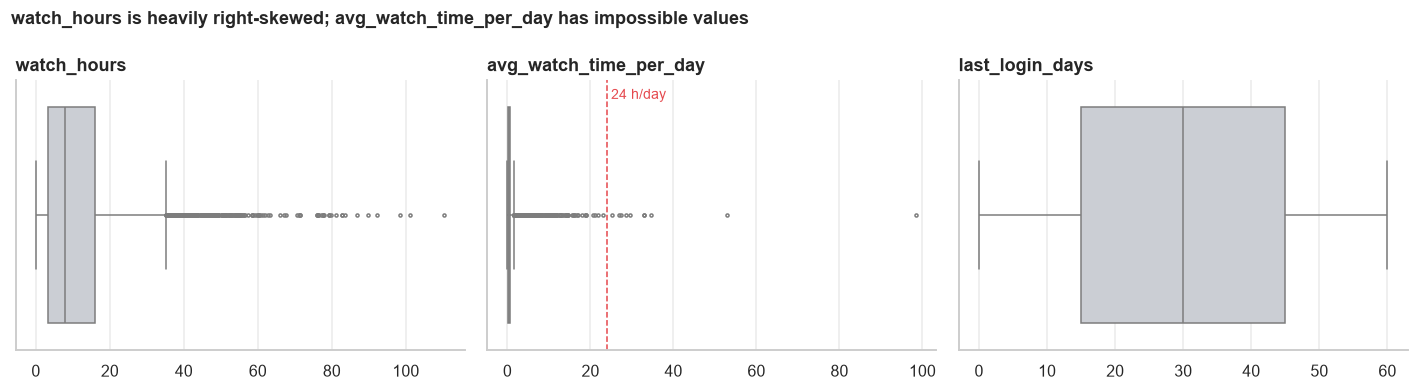

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["watch_hours", "avg_watch_time_per_day", "last_login_days"]):
    sns.boxplot(x=a[col], ax=ax, color="#C9CED6", fliersize=2, linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("")
axes[1].axvline(24, color=CHURN, ls="--", lw=1)
axes[1].text(24, -0.42, " 24 h/day", color=CHURN, fontsize=9, va="bottom")
fig.suptitle("watch_hours is heavily right-skewed; avg_watch_time_per_day has impossible values",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
savefig(fig, "01_a_outliers")
plt.show()

* Dataset B has **no IQR outliers**. All its columns sit in tidy bounded ranges (scores 1–10, months 1–24,
  hours 0.5–5), which is typical of synthetically generated data.
* In Dataset A, `watch_hours` has a long right tail (skew ≈ 2.3), with heavy viewers up to 110 h. These are
  plausible, so they should be **kept** (or log-transformed for Logistic Regression) rather than deleted.
  `avg_watch_time_per_day` is extremely skewed (skew ≈ 15.8) because of the derived-ratio issue in 3.2.

## 4. Target balance

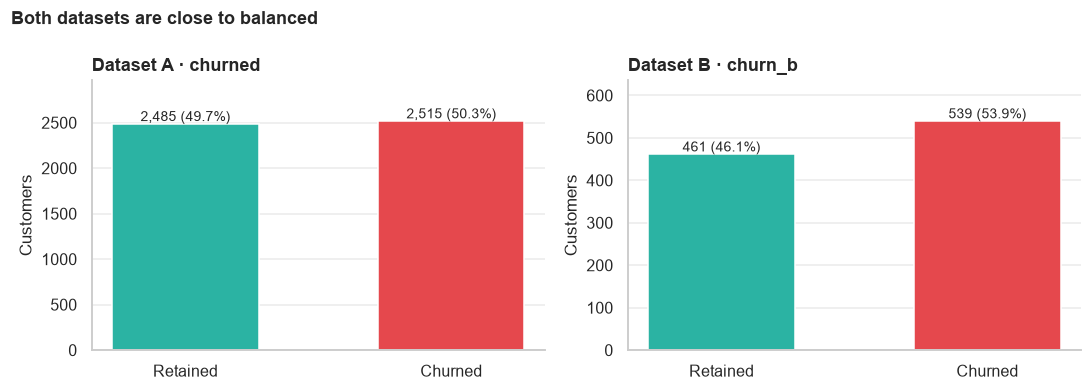

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, (title, s) in zip(axes, [("Dataset A · churned", a["status"]), ("Dataset B · churn_b", b["status"])]):
    counts = s.value_counts().reindex(["Retained", "Churned"])
    bars = ax.bar(counts.index, counts.values, color=[RETAINED, CHURN], width=0.55)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,} ({v / len(s):.1%})",
                ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("Customers")
    ax.set_ylim(0, counts.max() * 1.18)
    ax.grid(axis="x", visible=False)
fig.suptitle("Both datasets are close to balanced", x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
savefig(fig, "01_target_balance")
plt.show()

Dataset A is **50.3% churned** and Dataset B is **53.9% churned**. Neither is imbalanced, so resampling
(SMOTE, etc.) is not needed. We still report precision, recall, F1 and ROC-AUC, as the report specifies,
and stratify every split on the target.

## 5. Dataset A: numeric features vs churn

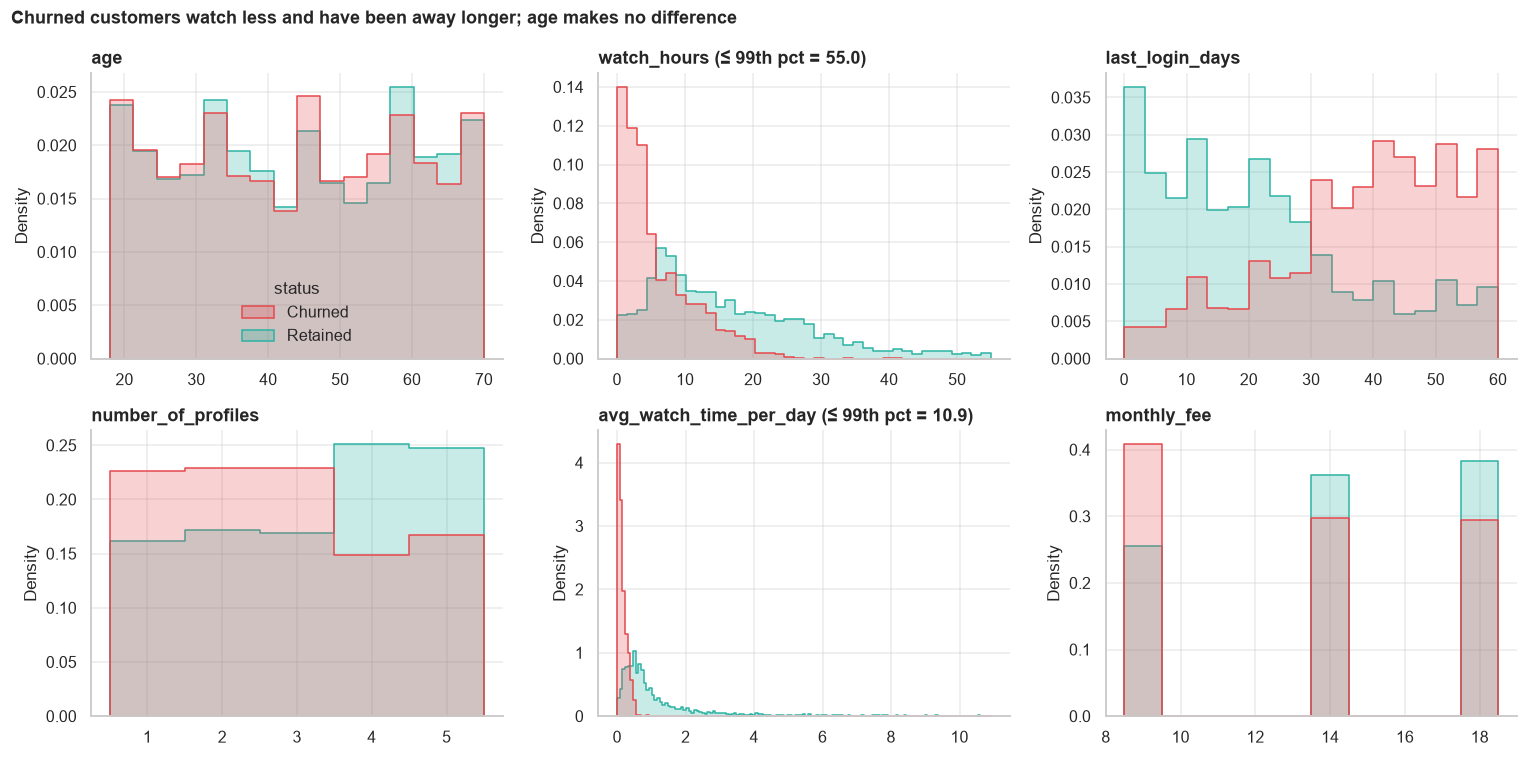

In [13]:
A_PLOT_NUMERIC = ["age", "watch_hours", "last_login_days", "number_of_profiles", "avg_watch_time_per_day", "monthly_fee"]
SKEWED = {"watch_hours", "avg_watch_time_per_day"}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, A_PLOT_NUMERIC):
    sub = a
    title = col
    if col in SKEWED:
        cap = a[col].quantile(0.99)
        sub = a[a[col] <= cap]
        title = f"{col} (≤ 99th pct = {cap:.1f})"
    discrete = a[col].nunique() <= 10
    sns.histplot(data=sub, x=col, hue="status", palette=STATUS_PALETTE, element="step",
                 stat="density", common_norm=False, discrete=discrete, ax=ax, legend=(col == "age"))
    ax.set_title(title)
    ax.set_xlabel("")
fig.suptitle("Churned customers watch less and have been away longer; age makes no difference",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
savefig(fig, "01_a_numeric_distributions")
plt.show()

In [14]:
a.groupby("status")[A_PLOT_NUMERIC].median().T.rename_axis("median by status")

status,Churned,Retained
median by status,,
age,44.000,44.000
watch_hours,4.060,13.860
last_login_days,41.000,19.000
number_of_profiles,3.000,3.000
avg_watch_time_per_day,0.120,0.720
monthly_fee,13.990,13.990


### 5.1 The 30-day cliff in `last_login_days`

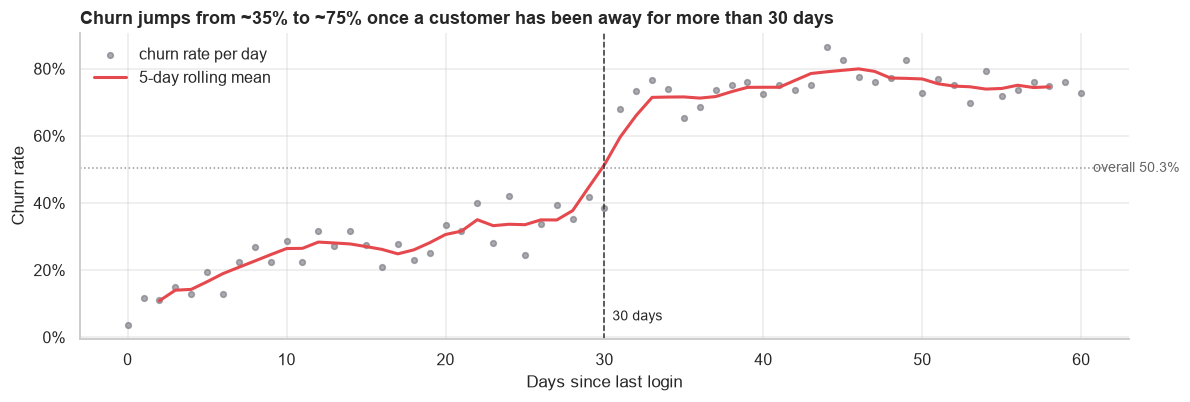

,churn_rate,customers
last_login_days,,
"(-1, 10]",0.170,907
"(10, 20]",0.267,775
"(20, 30]",0.353,849
"(30, 40]",0.725,822
"(40, 50]",0.781,843
"(50, 60]",0.746,804


In [15]:
overall = a[TARGET].mean()
by_day = a.groupby("last_login_days")[TARGET].mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.scatter(by_day.index, by_day.values, s=14, color=NEUTRAL, alpha=0.6, label="churn rate per day")
ax.plot(by_day.rolling(5, center=True).mean(), color=CHURN, lw=2, label="5-day rolling mean")
ax.axhline(overall, color="#999", ls=":", lw=1)
ax.text(60.5, overall, f" overall {overall:.1%}", va="center", fontsize=9, color="#666")
ax.axvline(30, color="#333", ls="--", lw=1)
ax.text(30.5, 0.05, "30 days", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Days since last login")
ax.set_ylabel("Churn rate")
ax.set_title("Churn jumps from ~35% to ~75% once a customer has been away for more than 30 days")
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "01_a_churn_by_last_login")
plt.show()

bins = pd.cut(a["last_login_days"], [-1, 10, 20, 30, 40, 50, 60])
a.groupby(bins, observed=True)[TARGET].agg(churn_rate="mean", customers="size")

This looks like a **threshold rule baked into the data generator** rather than a smooth human behaviour.
It is a strong signal and worth discussing in the report (it echoes the report's caveat that inactivity is
not the same as intent to leave).

## 6. Dataset A: categorical features vs churn

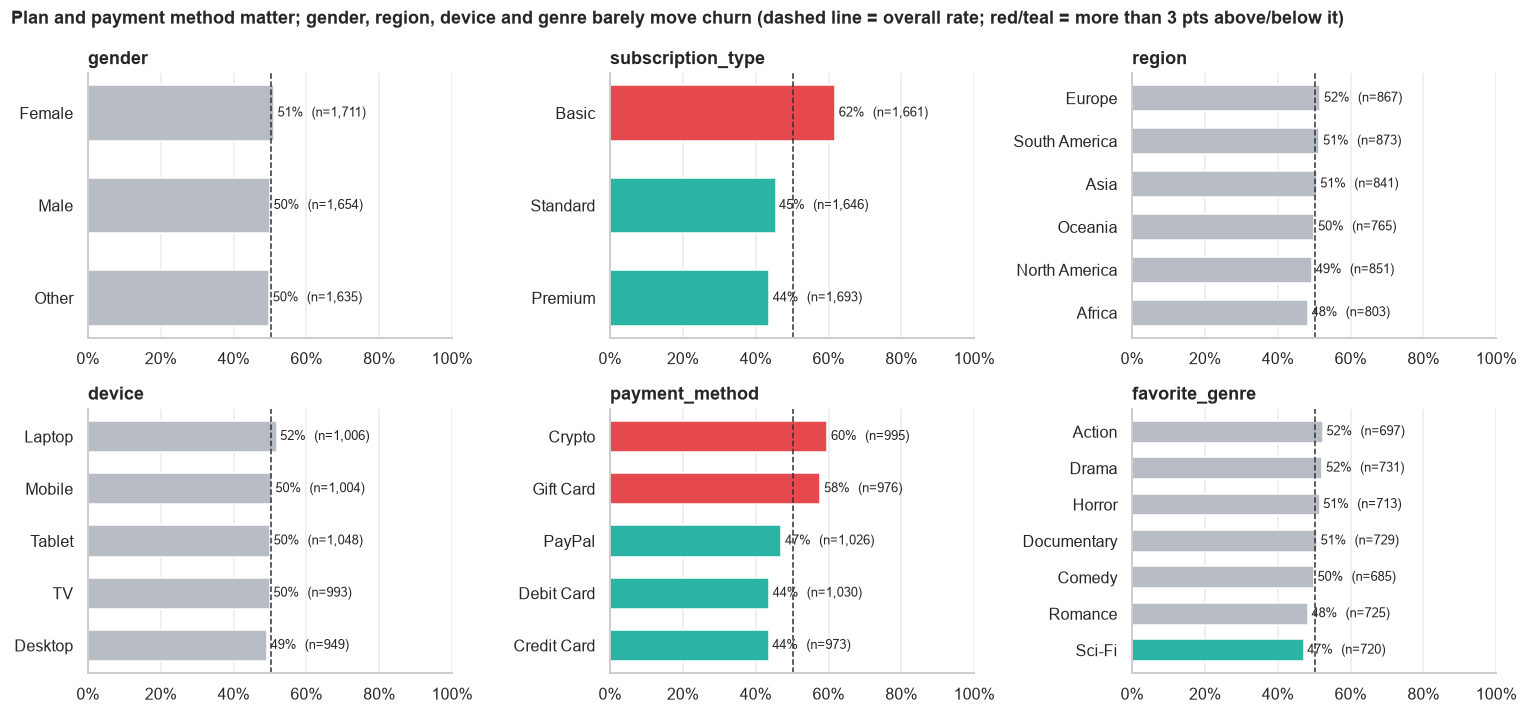

In [16]:
def plot_churn_rate_grid(df, cols, target, overall, title, fname, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        t = eda.churn_rate_by(df, col, target).sort_values("churn_rate")
        colors = [CHURN if r > overall + 0.03 else RETAINED if r < overall - 0.03 else "#B8BCC4"
                  for r in t["churn_rate"]]
        ax.barh(t[col].astype(str), t["churn_rate"], color=colors, height=0.6)
        for y, (r, n) in enumerate(zip(t["churn_rate"], t["customers"])):
            ax.text(r + 0.01, y, f"{r:.0%}  (n={n:,})", va="center", fontsize=8.5)
        ax.axvline(overall, color="#333", ls="--", lw=1)
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_title(col)
        ax.grid(axis="y", visible=False)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()

plot_churn_rate_grid(
    a, data.A_CATEGORICAL, TARGET, a[TARGET].mean(),
    "Plan and payment method matter; gender, region, device and genre barely move churn "
    "(dashed line = overall rate; red/teal = more than 3 pts above/below it)",
    "01_a_churn_rate_by_category",
)

In [17]:
pd.crosstab(a["subscription_type"], a["payment_method"], values=a[TARGET], aggfunc="mean").round(3)

payment_method,Credit Card,Crypto,Debit Card,Gift Card,PayPal
subscription_type,,,,,
Basic,0.594,0.627,0.601,0.647,0.626
Premium,0.336,0.577,0.349,0.524,0.388
Standard,0.362,0.592,0.365,0.567,0.385


* **Basic plan:** 61.8% churn vs about 44–45% for Standard and Premium.
* **Crypto (59.7%) and Gift Card (57.8%)** payers churn far more than card and PayPal payers (about 44–47%).
  Prepaid or non-recurring payment methods make cancelling easy.
* Gender, region, device and favourite genre are each within about 2–4 points of the overall rate. They
  will probably contribute little to the models, which matters because **these are exactly the columns we
  match on** with Dataset B.

### 6.1 Association of every A feature with churn

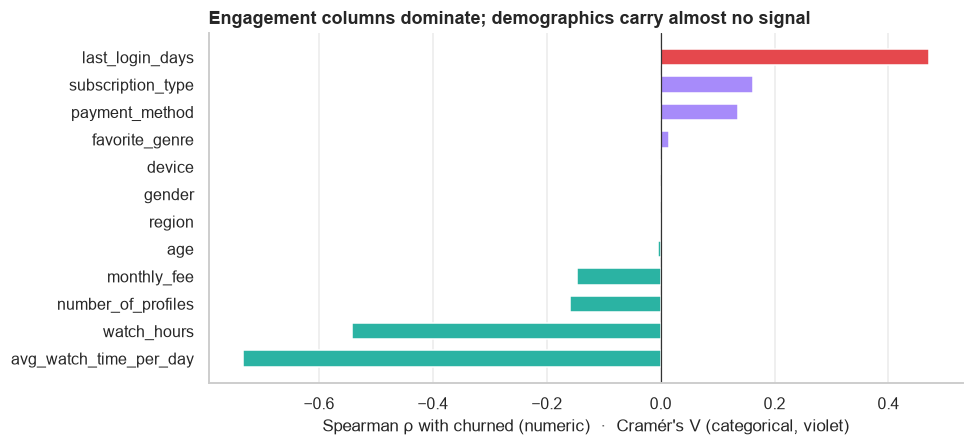

,feature,measure,value,strength
0,avg_watch_time_per_day,spearman,-0.734,0.734
1,watch_hours,spearman,-0.541,0.541
2,last_login_days,spearman,0.471,0.471
3,subscription_type,cramers_v,0.162,0.162
4,number_of_profiles,spearman,-0.159,0.159
5,monthly_fee,spearman,-0.148,0.148
6,payment_method,cramers_v,0.136,0.136
7,favorite_genre,cramers_v,0.014,0.014
8,age,spearman,-0.004,0.004
9,gender,cramers_v,0.000,0.000


In [18]:
assoc_a = eda.target_association(a, data.A_NUMERIC, data.A_CATEGORICAL, TARGET)

fig, ax = plt.subplots(figsize=(9, 4.2))
plot_df = assoc_a.sort_values("value")
colors = [B_COLOR if m == "cramers_v" else (CHURN if v > 0 else RETAINED)
          for m, v in zip(plot_df["measure"], plot_df["value"])]
ax.barh(plot_df["feature"], plot_df["value"], color=colors, height=0.6)
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlabel("Spearman ρ with churned (numeric)  ·  Cramér's V (categorical, violet)")
ax.set_title("Engagement columns dominate; demographics carry almost no signal")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "01_a_target_association")
plt.show()
assoc_a

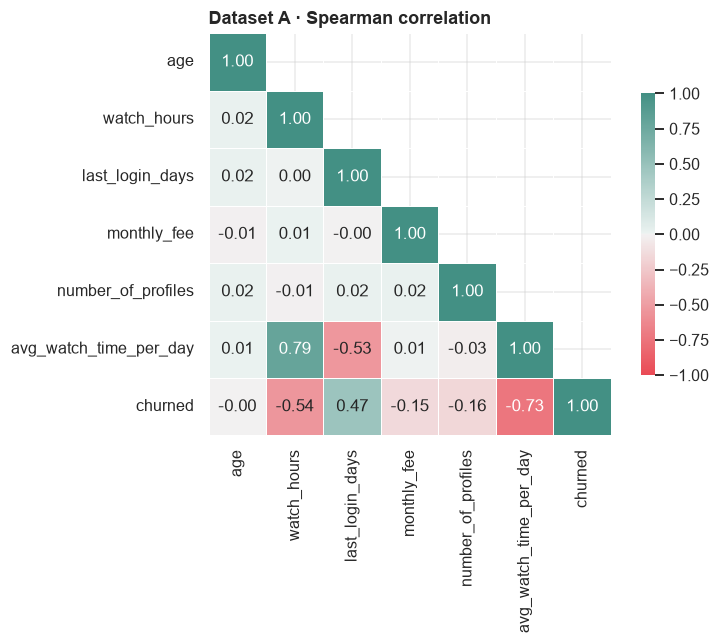

In [19]:
corr_a = a[data.A_NUMERIC + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr_a, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_a, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Dataset A · Spearman correlation")
fig.tight_layout()
savefig(fig, "01_a_correlation")
plt.show()

## 7. Dataset B: features vs churn

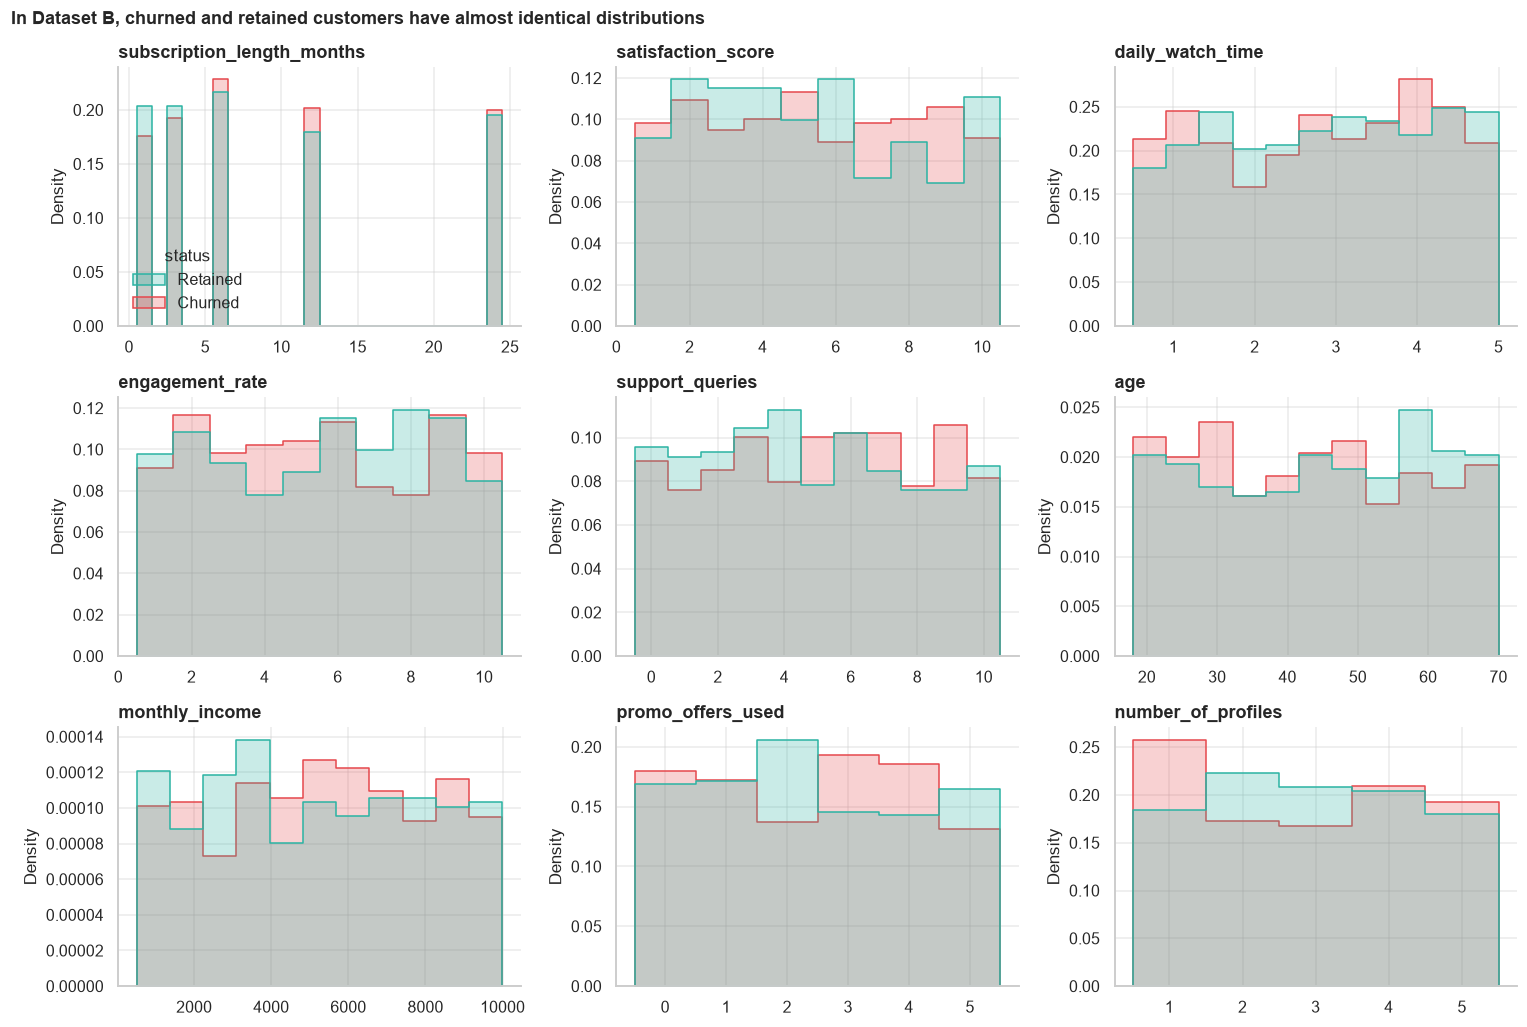

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9.5))
for ax, col in zip(axes.flat, data.B_NUMERIC):
    discrete = b[col].nunique() <= 25
    sns.histplot(data=b, x=col, hue="status", palette=STATUS_PALETTE, element="step", stat="density",
                 common_norm=False, discrete=discrete, ax=ax, legend=(col == data.B_NUMERIC[0]))
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("In Dataset B, churned and retained customers have almost identical distributions",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
savefig(fig, "01_b_numeric_distributions")
plt.show()

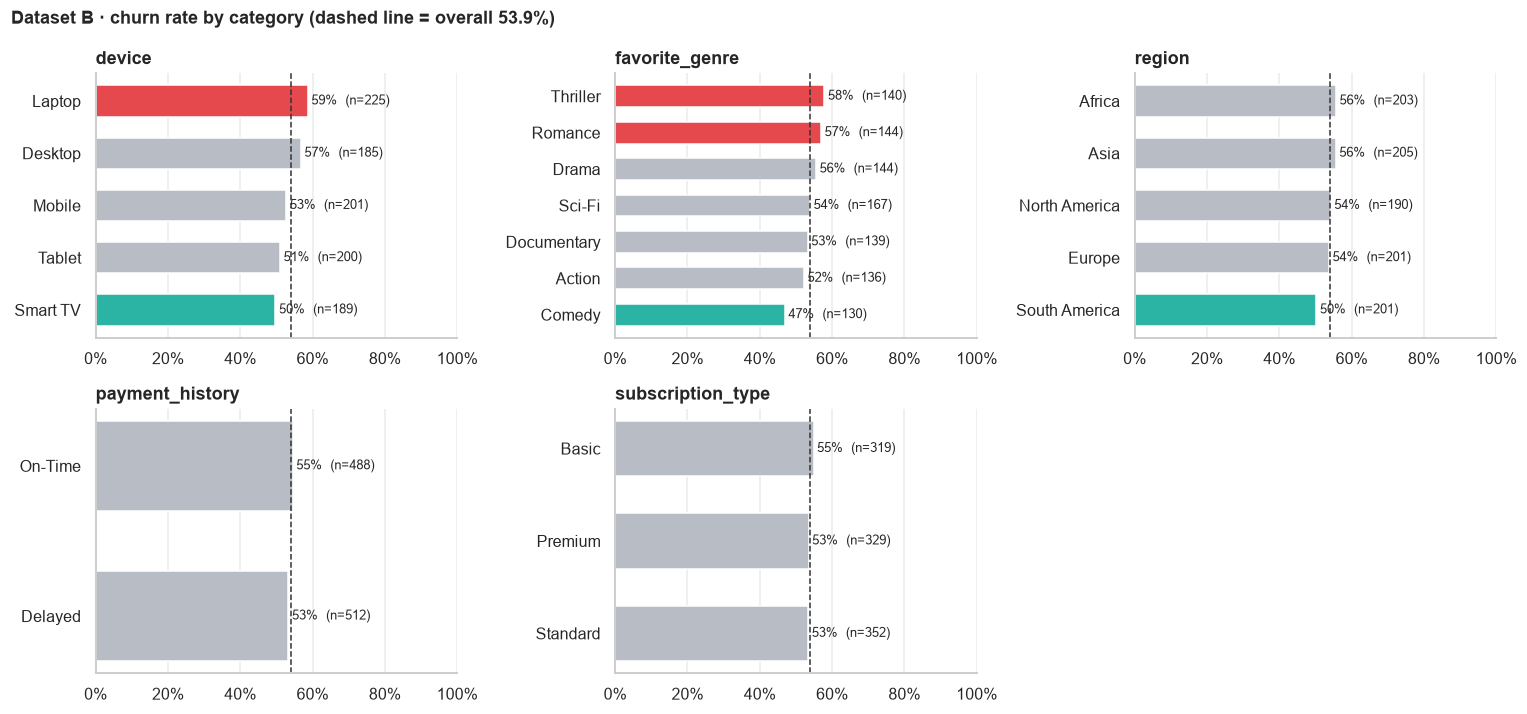

In [21]:
plot_churn_rate_grid(
    b, data.B_CATEGORICAL, "churn_b_flag", b["churn_b_flag"].mean(),
    "Dataset B · churn rate by category (dashed line = overall 53.9%)",
    "01_b_churn_rate_by_category",
)

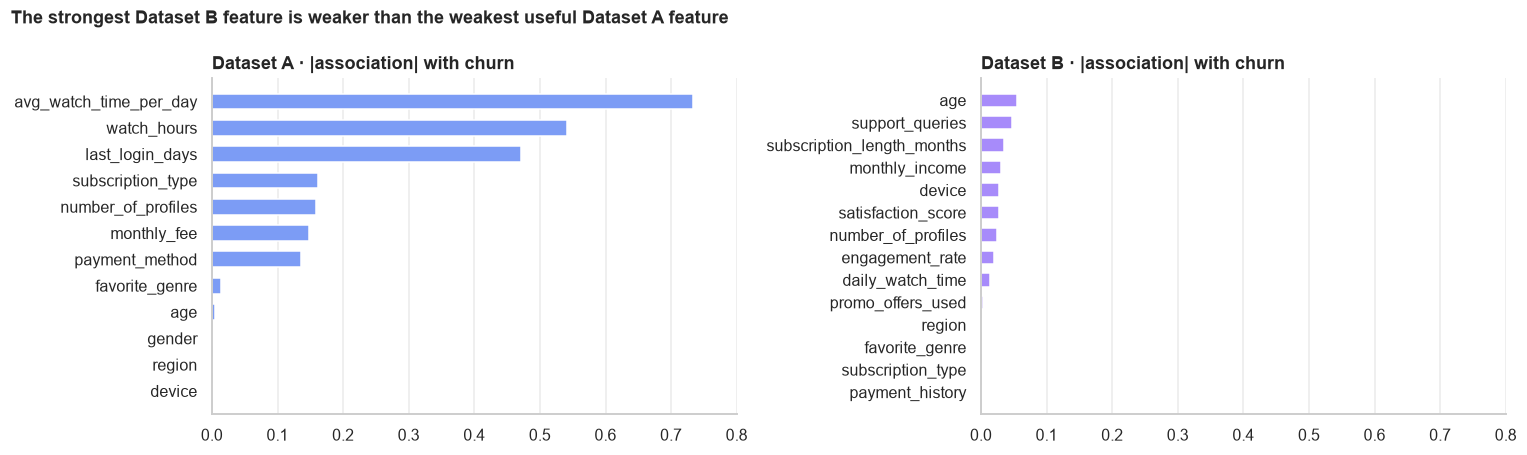

,feature,measure,value,strength
0,age,spearman,-0.055,0.055
1,support_queries,spearman,0.047,0.047
2,subscription_length_months,spearman,0.036,0.036
3,monthly_income,spearman,0.031,0.031
4,device,cramers_v,0.028,0.028
5,satisfaction_score,spearman,0.028,0.028
6,number_of_profiles,spearman,-0.024,0.024
7,engagement_rate,spearman,-0.020,0.020
8,daily_watch_time,spearman,-0.014,0.014
9,promo_offers_used,spearman,0.004,0.004


In [22]:
assoc_b = eda.target_association(b, data.B_NUMERIC, data.B_CATEGORICAL, "churn_b_flag")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, (name, df_) in zip(axes, [("Dataset A", assoc_a), ("Dataset B", assoc_b)]):
    p = df_.sort_values("strength")
    ax.barh(p["feature"], p["strength"], color=A_COLOR if name == "Dataset A" else B_COLOR, height=0.6)
    ax.set_title(f"{name} · |association| with churn")
    ax.set_xlim(0, 0.8)
    ax.grid(axis="y", visible=False)
fig.suptitle("The strongest Dataset B feature is weaker than the weakest useful Dataset A feature",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
savefig(fig, "01_b_vs_a_target_association")
plt.show()
assoc_b

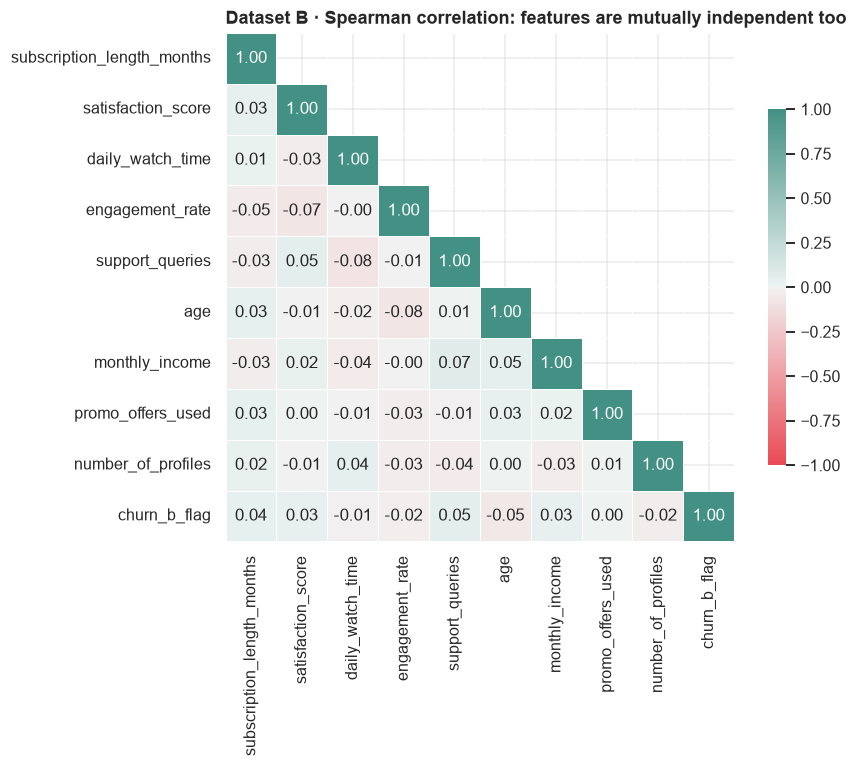

In [23]:
corr_b = b[data.B_NUMERIC + ["churn_b_flag"]].corr(method="spearman")
mask = np.triu(np.ones_like(corr_b, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr_b, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Dataset B · Spearman correlation: features are mutually independent too")
fig.tight_layout()
savefig(fig, "01_b_correlation")
plt.show()

Every Dataset B feature has |ρ| < 0.06 with `churn_b`, and the features are also uncorrelated with
**each other**. Real customer data almost never looks like this (satisfaction and engagement would normally
move together, for example). This strongly suggests Dataset B was generated by sampling each column
independently. Section 9 tests this directly.

## 8. Dataset A vs Dataset B: the common features

These are the columns that the similarity matching in notebook 04 will compare, so their **categories and
scales must line up**.

In [24]:
SHARED_CAT = ["subscription_type", "region", "device", "favorite_genre"]
rows = []
for col in SHARED_CAT:
    va, vb = set(a[col]), set(b[col])
    rows.append({"feature": col, "only in A": sorted(va - vb) or "-", "only in B": sorted(vb - va) or "-",
                 "shared values": len(va & vb)})
pd.DataFrame(rows)

,feature,only in A,only in B,shared values
0,subscription_type,-,-,3
1,region,[Oceania],-,5
2,device,[TV],[Smart TV],4
3,favorite_genre,[Horror],[Thriller],6


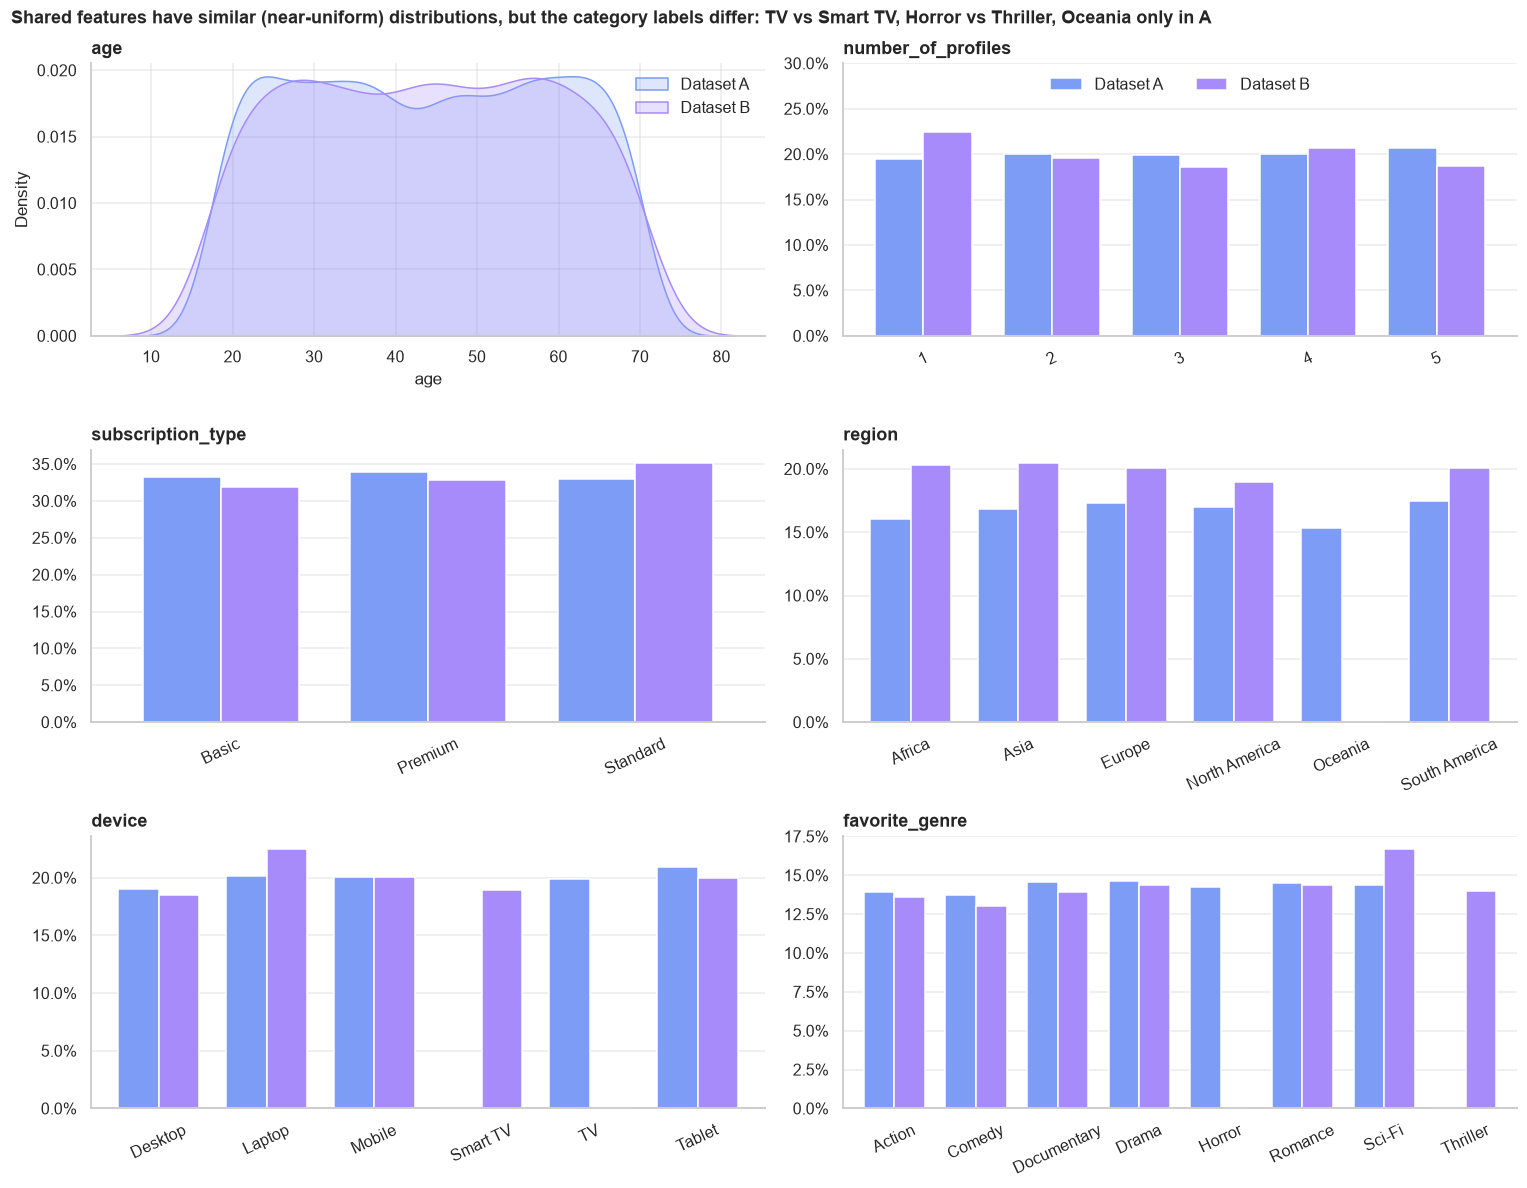

In [25]:
def shares(col):
    return pd.concat([a[col].value_counts(normalize=True).rename("Dataset A"),
                      b[col].value_counts(normalize=True).rename("Dataset B")], axis=1).fillna(0)

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
ax = axes[0, 0]
sns.kdeplot(a["age"], ax=ax, color=A_COLOR, label="Dataset A", fill=True, alpha=0.25)
sns.kdeplot(b["age"], ax=ax, color=B_COLOR, label="Dataset B", fill=True, alpha=0.25)
ax.set_title("age")
ax.legend()
for ax, col in zip(axes.flat[1:], ["number_of_profiles"] + SHARED_CAT):
    shares(col).sort_index().plot.bar(ax=ax, color=[A_COLOR, B_COLOR], width=0.75, rot=25, legend=False)
    ax.set_title(col)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
axes[0, 1].legend(["Dataset A", "Dataset B"], loc="upper center", ncol=2)
axes[0, 1].set_ylim(0, 0.3)
fig.suptitle("Shared features have similar (near-uniform) distributions, but the category labels differ: "
             "TV vs Smart TV, Horror vs Thriller, Oceania only in A",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
savefig(fig, "01_common_features_comparison")
plt.show()

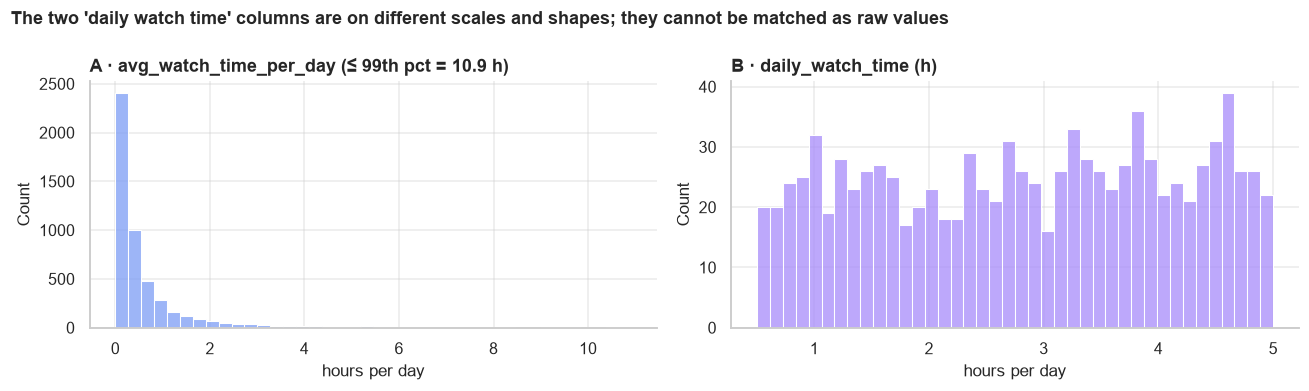

,A avg_watch_time_per_day,B daily_watch_time
count,"5,000.000","1,000.000"
mean,0.875,2.829
std,2.620,1.303
min,0.000,0.500
25%,0.110,1.650
50%,0.290,2.890
75%,0.720,3.933
max,98.420,5.000


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
cap = a["avg_watch_time_per_day"].quantile(0.99)
sns.histplot(a.loc[a["avg_watch_time_per_day"] <= cap, "avg_watch_time_per_day"], ax=axes[0], color=A_COLOR, bins=40)
axes[0].set_title(f"A · avg_watch_time_per_day (≤ 99th pct = {cap:.1f} h)")
sns.histplot(b["daily_watch_time"], ax=axes[1], color=B_COLOR, bins=40)
axes[1].set_title("B · daily_watch_time (h)")
for ax in axes:
    ax.set_xlabel("hours per day")
fig.suptitle("The two 'daily watch time' columns are on different scales and shapes; they cannot be matched as raw values",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
savefig(fig, "01_watch_time_scales")
plt.show()

pd.DataFrame({"A avg_watch_time_per_day": a["avg_watch_time_per_day"].describe(),
              "B daily_watch_time": b["daily_watch_time"].describe()})

Harmonization work for **notebook 03** (Sukhraj):

| Feature | Issue | Options |
|---|---|---|
| `device` | A says `TV`, B says `Smart TV` | rename B → `TV` |
| `favorite_genre` | `Horror` only in A, `Thriller` only in B | merge into one `Horror/Thriller` category, or leave them unmatched |
| `region` | `Oceania` only in A (765 customers, 15%) | these customers can only match on the other features; check that they are not all dropped by the 0.6 threshold |
| watch time | A: median 0.29 h, long tail · B: uniform 0.5–5 h | match on percentile rank, or leave it out of the matching vector |
| `age`, `number_of_profiles`, `subscription_type` | none | use as-is |

## 9. How much churn signal does each dataset hold?

A quick diagnostic (**not** the Phase 6 models): a default Random Forest with 5-fold stratified
cross-validation on the raw features, scored by ROC-AUC. An AUC of 0.5 means no better than a coin flip.

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

def quick_auc(X, y):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
    rf = RandomForestClassifier(n_estimators=300, random_state=config.RANDOM_STATE, n_jobs=-1)
    return cross_val_score(rf, X, y, cv=cv, scoring="roc_auc")

ENGAGEMENT_A = ["watch_hours", "last_login_days", "avg_watch_time_per_day"]
X_a = pd.get_dummies(a.drop(columns=[ID, TARGET, "status"]), dtype=float)
X_a_noeng = pd.get_dummies(a.drop(columns=[ID, TARGET, "status"] + ENGAGEMENT_A), dtype=float)
X_b = pd.get_dummies(b.drop(columns=[ID, "churn_b", "status", "churn_b_flag"]), dtype=float)
y_b = b["churn_b_flag"]
rng = np.random.default_rng(config.RANDOM_STATE)

runs = {
    "A · all features": quick_auc(X_a, a[TARGET]),
    "A · without watch/login columns": quick_auc(X_a_noeng, a[TARGET]),
    "B · all features (predicting churn_b)": quick_auc(X_b, y_b),
    "B · shuffled labels (pure chance)": quick_auc(X_b, pd.Series(rng.permutation(y_b.to_numpy()))),
}
signal = pd.DataFrame({k: {"mean AUC": v.mean(), "std": v.std()} for k, v in runs.items()}).T
signal

,mean AUC,std
A · all features,0.998,0.001
A · without watch/login columns,0.614,0.016
B · all features (predicting churn_b),0.490,0.038
B · shuffled labels (pure chance),0.518,0.023


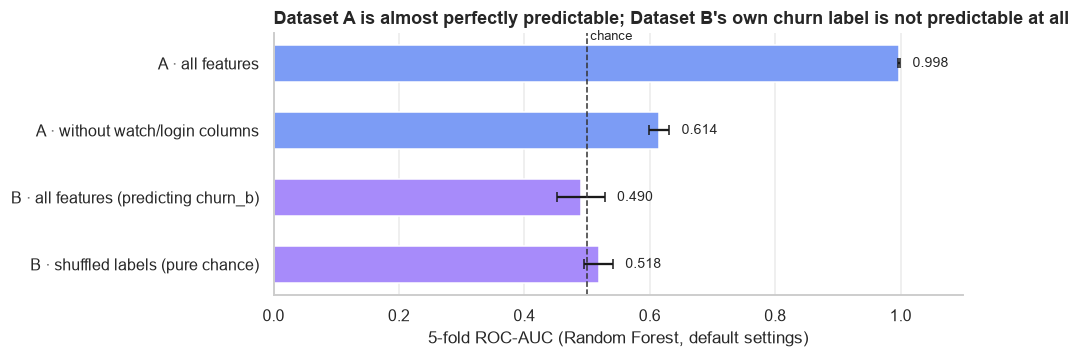

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.4))
p = signal.iloc[::-1]
colors = [B_COLOR if k.startswith("B") else A_COLOR for k in p.index]
ax.barh(p.index, p["mean AUC"], xerr=p["std"], color=colors, height=0.55, capsize=3)
for y, (v, sd) in enumerate(zip(p["mean AUC"], p["std"])):
    ax.text(v + sd + 0.02, y, f"{v:.3f}", va="center", fontsize=9)
ax.axvline(0.5, color="#333", ls="--", lw=1)
ax.text(0.505, 3.35, "chance", fontsize=8.5)
ax.set_xlim(0, 1.1)
ax.set_xlabel("5-fold ROC-AUC (Random Forest, default settings)")
ax.set_title("Dataset A is almost perfectly predictable; Dataset B's own churn label is not predictable at all")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "01_signal_check")
plt.show()

## 10. Key findings

**Data quality**
1. Both datasets are complete: **0 missing cells, 0 duplicate rows, 0 duplicate IDs**. Cleaning is about invalid values and redundancy, not imputation.
2. `avg_watch_time_per_day` is **exactly** `watch_hours / (last_login_days + 1)` (100% of rows). It is a derived column, and **10 rows exceed 24 h/day**, which is impossible.
3. `monthly_fee` is a one-to-one recoding of `subscription_type` (8.99 / 13.99 / 17.99), so it is redundant.
4. `watch_hours` is right-skewed (skew 2.3, 238 IQR outliers up to 110 h). These are plausible heavy viewers, not errors. Dataset B has no outliers at all.

**Target**

5. Both targets are close to balanced: A **50.3%** churn, B **53.9%**. No resampling is needed, and we stratify all splits.

**What drives churn in Dataset A**

6. **Engagement dominates.** Churn jumps from **17–35%** for customers seen in the last 30 days to **73–78%** after 30 days away. Median watch hours are **4.1 h for churned vs 13.9 h for retained** customers.
7. **Plan and payment matter:** Basic plan 62% vs about 44% for Standard and Premium. Crypto 60% and Gift Card 58% vs about 44–47% for cards and PayPal. Customers with 4–5 profiles churn less than those with 1–3.
8. **Gender, region, device and favourite genre carry almost no signal** (every category is within about 3 points of the overall rate).
9. A default Random Forest reaches **ROC-AUC 0.998** on Dataset A. Without the three watch/login columns it drops to **0.614**. The dataset is almost perfectly separable, and nearly all of that separability comes from engagement.

**Dataset B**

10. **No B feature is associated with B's own churn label** (every |ρ| < 0.06, and Cramér's V is about 0). The features are also uncorrelated with each other.
11. A Random Forest predicting `churn_b` from all of B's features scores **AUC 0.490**, which is no better than shuffled labels (0.518). **Dataset B appears to be independently sampled synthetic data with no churn signal.**

**Common features (for matching)**

12. The shared features (age, profiles, plan, region, device, genre) are near-uniformly distributed in both datasets, and the label mismatches are confirmed: `TV`/`Smart TV`, `Horror`/`Thriller`, and `Oceania` (15% of A) has no counterpart in B. The two daily-watch-time columns are on different scales, so they cannot be matched as raw values.

---

### Implications for the next phases

* **Notebook 02 (cleaning, Aayush):**
  - Fix or recompute the 10 rows above 24 h/day.
  - Decide between keeping `avg_watch_time_per_day` (derived) and dropping it.
  - Drop `monthly_fee` as redundant with `subscription_type`.
  - Keep the `watch_hours` outliers, with a log transform for Logistic Regression.
* **Notebook 03 (feature mapping, Sukhraj):**
  - Apply the harmonization table in section 8.
  - Remember that the matching features are exactly the ones with the least churn signal, so neighbours will be "similar" mainly on demographics.
* **Notebook 05 (augmented EDA, Sukhraj):**
  - Averaging 5 neighbours compresses variance (regression to the mean). Compare the spread of each transferred feature with the original B column.
* **Expected outcome of the research question:**
  - Dataset A is already at AUC ≈ 1.0, which leaves no room for improvement.
  - Dataset B's features carry no churn information even within B.
  - So the honest expectation is **A_augmented ≈ A_matched ≈ A_random**, or a small drop from added noise. That is still a valid, defensible answer to the research question, and the `A_random` control is what makes it convincing.
* **Proposed extra experiment (to agree as a team, since it goes beyond the report):** repeat the comparison on a *harder* version of A without the watch/login columns (AUC ≈ 0.61). That version has room to improve, so it is a fairer test of whether the transferred features help.